dataset names

`physionet-data.mimiciv_ecg`  
`physionet-data.mimiciv_ed`  
`physionet-data.mimiciv_3_1_hosp`  
`physionet-data.mimiciv_3_1_icu`  
`physionet-data.mimiciv_note`  

Yes exactly. Breaking it down:

l0 = first LSTM layer (input size 236 → hidden size 256)
l1 = second LSTM layer (input size 256 → hidden size 256)

For each layer there are four sets of weights/biases, split into two groups:

weight_ih -- input-to-hidden weights. For each of the 4 gates (input, forget, cell, output) there's a weight matrix connecting the input to that gate:

weight_ih_l0: shape (4×256, 236) -- 4 gates × hidden size, by input size
weight_ih_l1: shape (4×256, 256) -- same but input is now the hidden state from l0
weight_hh -- hidden-to-hidden weights. The recurrent connection -- previous hidden state feeding into the current timestep's gates:

weight_hh_l0: shape (4×256, 256)
weight_hh_l1: shape (4×256, 256)
bias_ih and bias_hh -- one bias vector per gate per layer, shape (4×256,) each. PyTorch splits the bias into two (ih and hh) but in practice they just add together -- it's equivalent to one bias but kept separate for historical reasons.

So at each timestep, for each gate: gate = weight_ih @ x_t + bias_ih + weight_hh @ h_{t-1} + bias_hh. The 4×256 dimension is the four gates stacked vertically in one matrix for computational efficiency.

Practice again:
- generator
- decorator
- context manager
- regex

In [1]:
from modeling.lstm.model import LSTMSequenceModel
from torch.utils.data import ConcatDataset
import torch
import shap
import pandas as pd
from utils.load_yaml_helper import load_yaml
import torch.nn as nn
from modeling.data_prep import lstm
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)

settings = load_yaml("project_setup/settings.yaml")
hf_cfg = settings['hugging_face']

In [6]:
import pickle

with open("modeling/artifacts/random_forest/random_forest_20260413_130908.pkl", "rb") as f:
    model = pickle.load(f)

In [16]:
model.feature_names_in_[180:210]

array(['Beta Blocker', 'Bronchodilator', 'Calcium Channel Blocker',
       'Corticosteroid', 'Diuretic', 'GI - Acid Suppression', 'IV Fluid',
       'Insulin/Glucose', 'Nitrate', 'Other', 'ecg_status_Normal',
       'ecg_status_Moderate', 'ecg_status_Acute', 'rad_status_Normal',
       'rad_status_Moderate', 'rad_status_Acute', 'vitals_checked',
       'labs_ordered', 'micro_ordered', 'in_ed', 'in_ward', 'gender',
       'anchor_age', 'acuity', 'pain_missing', 'heartrate_missing',
       'o2sat_missing', 'acuity_missing', 'resprate_missing',
       'sbp_missing'], dtype=object)

In [2]:
pd.set_option("display.max_columns", None)

df = pd.read_parquet("modeling/artifacts/random_forest/test_20260413_130908.parquet")

df.head()

,ed_stay_id,subject_id,current_temperature,current_heartrate,current_resprate,current_o2sat,current_sbp,current_dbp,current_pain,current_mean_arterial_pressure,Blood Gas-Blood_Pending,Blood Gas-Blood_Normal,Blood Gas-Blood_Abnormal,Blood Gas-Other Body Fluid_Pending,Blood Gas-Other Body Fluid_Normal,Blood Gas-Other Body Fluid_Abnormal,Chemistry-Ascites_Pending,Chemistry-Ascites_Normal,Chemistry-Ascites_Abnormal,Chemistry-Blood_Pending,Chemistry-Blood_Normal,Chemistry-Blood_Abnormal,Chemistry-Cerebrospinal Fluid_Pending,Chemistry-Cerebrospinal Fluid_Normal,Chemistry-Cerebrospinal Fluid_Abnormal,Chemistry-Joint Fluid_Pending,Chemistry-Joint Fluid_Normal,Chemistry-Joint Fluid_Abnormal,Chemistry-Other Body Fluid_Pending,Chemistry-Other Body Fluid_Normal,Chemistry-Other Body Fluid_Abnormal,Chemistry-Pleural_Pending,Chemistry-Pleural_Normal,Chemistry-Pleural_Abnormal,Chemistry-Stool_Pending,Chemistry-Stool_Normal,Chemistry-Stool_Abnormal,Chemistry-Urine_Pending,Chemistry-Urine_Normal,Chemistry-Urine_Abnormal,Hematology-Ascites_Pending,Hematology-Ascites_Normal,Hematology-Ascites_Abnormal,Hematology-Blood_Pending,Hematology-Blood_Normal,Hematology-Blood_Abnormal,Hematology-Bone Marrow_Pending,Hematology-Bone Marrow_Normal,Hematology-Bone Marrow_Abnormal,Hematology-Cerebrospinal Fluid_Pending,Hematology-Cerebrospinal Fluid_Normal,Hematology-Cerebrospinal Fluid_Abnormal,Hematology-Joint Fluid_Pending,Hematology-Joint Fluid_Normal,Hematology-Joint Fluid_Abnormal,Hematology-Other Body Fluid_Pending,Hematology-Other Body Fluid_Normal,Hematology-Other Body Fluid_Abnormal,Hematology-Pleural_Pending,Hematology-Pleural_Normal,Hematology-Pleural_Abnormal,Hematology-Stool_Pending,Hematology-Stool_Normal,Hematology-Stool_Abnormal,Hematology-Urine_Pending,Hematology-Urine_Normal,Hematology-Urine_Abnormal,ABSCESS_Pending,ABSCESS_Negative,ABSCESS_Positive,ABSCESS_Other,BILE_Pending,BILE_Negative,BILE_Positive,BILE_Other,BLOOD CULTURE_Pending,BLOOD CULTURE_Negative,BLOOD CULTURE_Positive,BLOOD CULTURE_Other,BRONCHOALVEOLAR LAVAGE_Pending,BRONCHOALVEOLAR LAVAGE_Negative,BRONCHOALVEOLAR LAVAGE_Positive,BRONCHOALVEOLAR LAVAGE_Other,Blood (CMV AB)_Pending,Blood (CMV AB)_Negative,Blood (CMV AB)_Positive,Blood (CMV AB)_Other,Blood (EBV)_Pending,Blood (EBV)_Negative,Blood (EBV)_Positive,Blood (EBV)_Other,CSF;SPINAL FLUID_Pending,CSF;SPINAL FLUID_Negative,CSF;SPINAL FLUID_Positive,CSF;SPINAL FLUID_Other,"FLUID,OTHER_Pending","FLUID,OTHER_Negative","FLUID,OTHER_Positive","FLUID,OTHER_Other",IMMUNOLOGY_Pending,IMMUNOLOGY_Negative,IMMUNOLOGY_Positive,IMMUNOLOGY_Other,JOINT FLUID_Pending,JOINT FLUID_Negative,JOINT FLUID_Positive,JOINT FLUID_Other,MRSA SCREEN_Pending,MRSA SCREEN_Negative,MRSA SCREEN_Positive,MRSA SCREEN_Other,OTHER_Pending,OTHER_Negative,OTHER_Positive,OTHER_Other,PERITONEAL FLUID_Pending,PERITONEAL FLUID_Negative,PERITONEAL FLUID_Positive,PERITONEAL FLUID_Other,PLEURAL FLUID_Pending,PLEURAL FLUID_Negative,PLEURAL FLUID_Positive,PLEURAL FLUID_Other,Rapid Respiratory Viral Screen & Culture_Pending,Rapid Respiratory Viral Screen & Culture_Negative,Rapid Respiratory Viral Screen & Culture_Positive,Rapid Respiratory Viral Screen & Culture_Other,SEROLOGY/BLOOD_Pending,SEROLOGY/BLOOD_Negative,SEROLOGY/BLOOD_Positive,SEROLOGY/BLOOD_Other,SPUTUM_Pending,SPUTUM_Negative,SPUTUM_Positive,SPUTUM_Other,STOOL_Pending,STOOL_Negative,STOOL_Positive,STOOL_Other,SWAB_Pending,SWAB_Negative,SWAB_Positive,SWAB_Other,TISSUE_Pending,TISSUE_Negative,TISSUE_Positive,TISSUE_Other,URINE_Pending,URINE_Negative,URINE_Positive,URINE_Other,recon_ace_inhibitor,recon_analgesic___nsaid,recon_analgesic___opioid_nsaid,recon_antiarrhythmic,recon_antibiotic,recon_anticoagulant,recon_anticonvulsant,recon_antiemetic,recon_antiplatelet,recon_antipsychotic,recon_benzodiazepine___sedative_anxiolytic,recon_beta_blocker,recon_bronchodilator,recon_calcium_channel_blocker,recon_corticosteroid,recon_diuretic,recon_gi___acid_suppression,recon_insulin_glucose,recon_nitrate,ACE Inhibitor,Analges

In [16]:
model_path = "modeling/artifacts/lstm/lstm_weights_20260414_235511.pt"
seq_model_weights = torch.load(model_path, map_location=torch.device('cpu'))

seq_model = LSTMSequenceModel()

seq_model.load_state_dict(seq_model_weights)

seq_model.train()

LSTMSequenceModel(
  (lstm): LSTM(236, 256, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)

In [57]:
pd.set_option("display.max_columns", None)

streamlit_df = pd.read_parquet("streamlit/step_features.parquet")
streamlit_df.head()

,ed_stay_id,step_idx,time,in_ed,in_ward,terminal_code,current_temperature,current_heartrate,current_resprate,current_o2sat,current_sbp,current_dbp,current_pain,Chemistry-Blood_Pending,Chemistry-Blood_Normal,Chemistry-Blood_Abnormal,Hematology-Blood_Pending,Hematology-Blood_Normal,Hematology-Blood_Abnormal,Blood Gas-Blood_Pending,Blood Gas-Blood_Normal,Blood Gas-Blood_Abnormal,BLOOD CULTURE_Pending,BLOOD CULTURE_Negative,BLOOD CULTURE_Positive,ecg_status_Normal,ecg_status_Moderate,ecg_status_Acute,rad_status_Normal,rad_status_Moderate,rad_status_Acute,Antibiotic,IV Fluid,Analgesic - Opioid/NSAID,Analgesic - Acetaminophen,Antiemetic,Anticoagulant,Corticosteroid,Benzodiazepine - Sedative/Anxiolytic,Beta Blocker,Diuretic,Bronchodilator,p_icu
0,30000177,110,2143-12-27 22:50:00,1,0,0,-0.460487,1.410287,0.084912,0.9961,2.768631,2.675339,1.80626,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.008931
1,30000177,111,2143-12-27 23:00:00,1,0,0,-0.460487,1.410287,0.084912,0.9961,2.768631,2.675339,1.80626,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.001004
2,30000177,112,2143-12-27 23:37:00,1,0,0,-0.460487,1.410287,0.084912,0.9961,2.768631,2.675339,1.80626,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.001664
3,30000177,113,2143-12-27 23:40:00,1,0,0,-0.460487,1.410287,0.084912,0.9961,2.768631,2.675339,1.80626,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.002761
4,30000177,114,2143-12-28 00:02:00,1,0,0,-0.460487,1.410287,0.084912,0.9961,2.768631,2.675339,1.80626,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.003857


In [19]:
full_data, state_cols = lstm.load_and_prep_lstm(hf_cfg=hf_cfg)

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/27 [00:00<?, ?it/s]

In [30]:
modeling_data = lstm.remove_outlier_stays(full_data)

df_train, df_test, df_val = lstm.split_data(df=modeling_data, train_size=0.6)

train, test, val, scaler = lstm.scaling(train=df_train, test=df_test, val=df_val)

s_train, y_train, len_train = lstm.pad_stays(df=train, state_cols=state_cols)
s_train = torch.tensor(s_train)
# y_train = torch.tensor(y_train)
# len_train = torch.tensor(len_train)

s_test, y_test, len_test = lstm.pad_stays(df=test, state_cols=state_cols)
s_test = torch.tensor(s_test)
# y_test = torch.tensor(y_test)
# len_test = torch.tensor(len_test)

In [40]:
s_val, y_val, len_val = lstm.pad_stays(df=test, state_cols=state_cols)
s_val = torch.tensor(s_val)
# y_test = torch.tensor(y_test)
# len_test = torch.tensor(len_test)

In [41]:
combined_dataset = pd.concat([
        val.sort_values(['ed_stay_id', 'step_idx']),
        test.sort_values(['ed_stay_id', 'step_idx']),
    ]).reset_index(drop=True)

In [43]:
combined_tensor_dataset = torch.concat([s_val, s_test])

In [51]:
slim = combined_tensor_dataset[:10_000, :, :]

In [53]:
torch.save(slim.clone(), f="patients.pt")

In [ ]:
# This takes the median value across all features and creares a baseline.  Probability output was 95/5, true distro was 92/8

mask = torch.arange(100).unsqueeze(0) < len_train.unsqueeze(1)
mask = mask.unsqueeze(2).expand_as(s_train)

baseline = s_train[mask].view(-1, 236).median(dim=0).values
baseline = baseline.unsqueeze(0).unsqueeze(0).expand(1, 100, 236)

In [54]:
reference_data = torch.randperm(s_train.shape[0], generator=torch.Generator().manual_seed(10))[:200]
baseline = s_train[reference_data]

In [55]:
torch.save(baseline, f='streamlit/baseline_tensors.pt')

In [10]:
tst_idx = torch.randperm(s_test.shape[0], generator=torch.Generator().manual_seed(10))[:20]
tst_data = s_test[tst_idx].to(torch.device('cpu'))

In [11]:
class ModelWrapper(nn.Module):
    def forward(self, x, lengths=None):
        if lengths is None:
            # compute actual lengths from non-zero rows
            lengths = (x.abs().sum(dim=-1) != 0).sum(dim=1).clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = seq_model.lstm(packed)
        return seq_model.fc(h_n[-1])
    

In [12]:
wrapper = ModelWrapper().to(torch.device('cpu'))

In [24]:
explainer = shap.GradientExplainer(model=wrapper, data=baseline)

In [25]:
shap_values = explainer.shap_values(tst_data)

In [ ]:
# Aggregated random samples but I don't think that changes the results
baseline = torch.cat([s_train[torch.randperm(s_train.shape[0], generator=torch.Generator().manual_seed(i))[:300]] for i in range(5)])
explainer = shap.GradientExplainer(model=wrapper, data=baseline)
shap_values = explainer.shap_values(tst_data)

In [ ]:
# class ModelWrapper(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.lstm = seq_model.lstm
#         self.fc = seq_model.fc

#     def forward(self, x):
#         _, (h_n, _) = self.lstm(x)  # feed full padded sequence, no packing
#         return self.fc(h_n[-1])
    
# wrapper = ModelWrapper().to(torch.device('cpu'))

# reference_data = torch.randperm(s_train.shape[0], generator=torch.Generator().manual_seed(10))[:300]
# baseline = s_train[reference_data]

# explainer = shap.DeepExplainer(model=wrapper, data=baseline)
# shap_values = explainer.shap_values(tst_data)

In [130]:
raw_icu_shape = shap_values[..., 1]

In [131]:
mean_shap = np.abs(raw_icu_shape).mean(axis=1).mean(axis=0)

In [132]:
top_idx = np.argsort(mean_shap)[::-1][:20]
top_values = mean_shap[top_idx]
top_names = [state_cols[i] for i in top_idx]

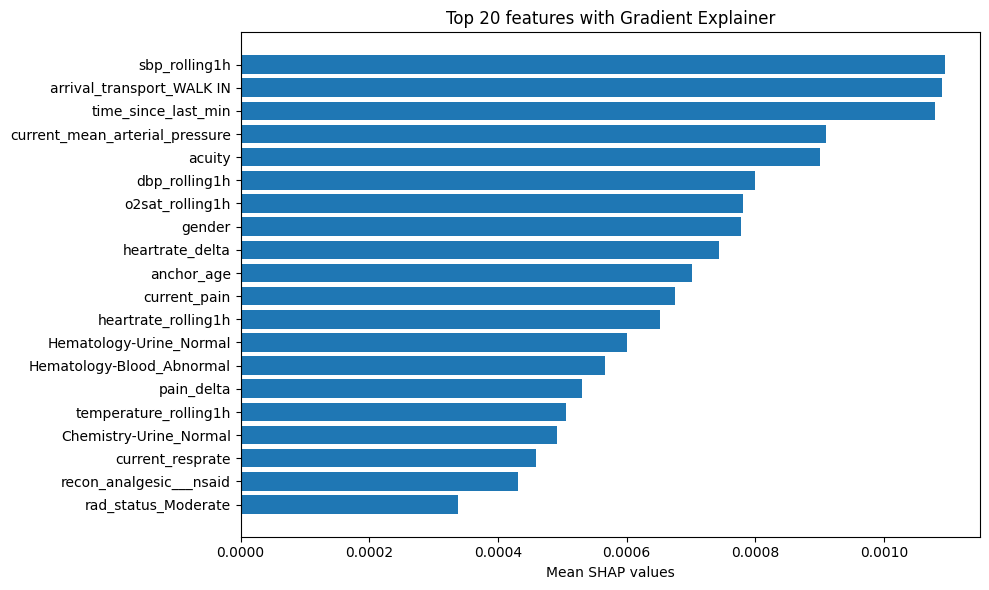

In [113]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_names[::-1], top_values[::-1])
ax.set_xlabel("Mean SHAP values")
ax.set_title("Top 20 features with Gradient Explainer")
plt.tight_layout()
plt.show()

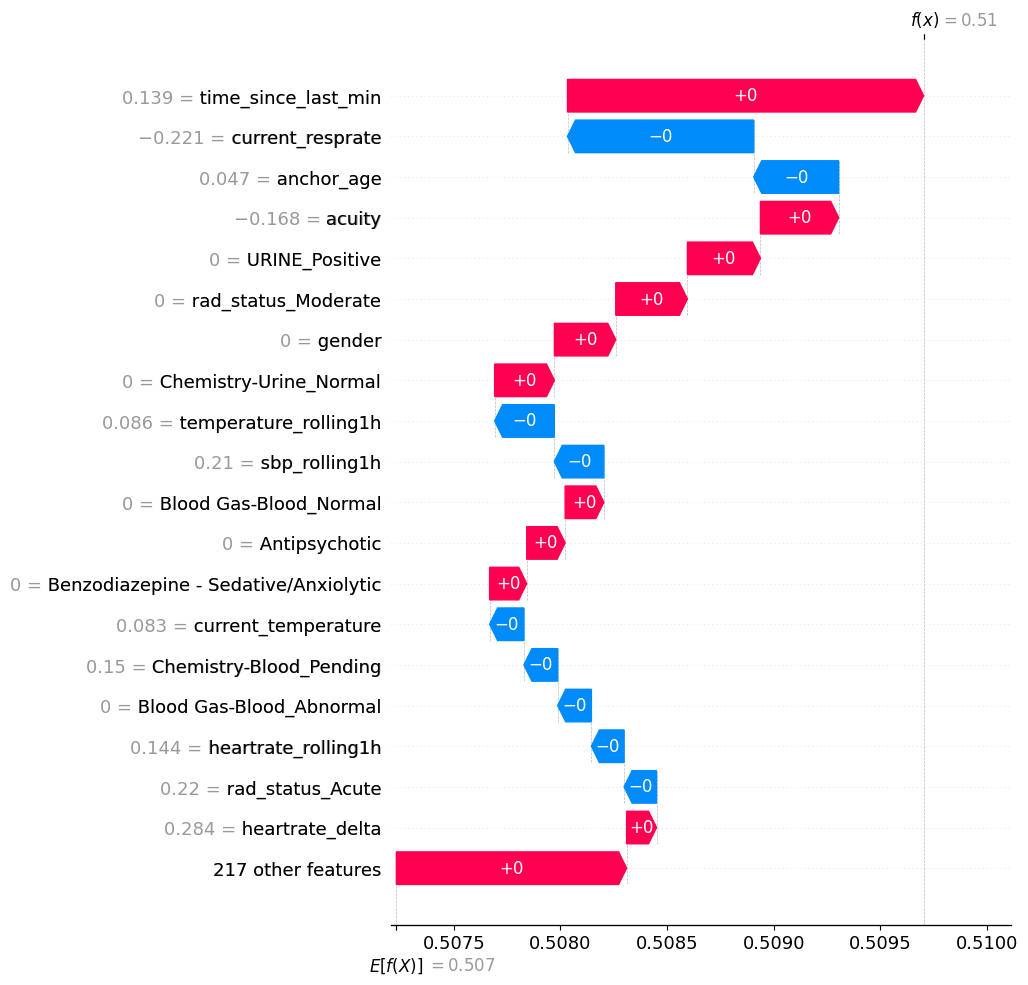

In [136]:
# --- pick a sample ---
sample_idx = 9  # change to any index in [0, 199]

# shap_values shape: (200, 100, 236, 2)
# sum across timesteps for the ICU class
sample_shap = shap_values[sample_idx, :, :, 1].sum(axis=0)  # (236,)

# --- base value: run wrapper on baseline in eval mode ---
# baseline shape must match model input: (1, 100, 236)
wrapper.eval()
with torch.no_grad():
    base_logits = wrapper(baseline.to(torch.device('cpu')))  # (1, 2) or (1, T, 2) depending on wrapper
    base_prob = torch.softmax(base_logits, dim=-1)[:, 1].mean().item()  # Aggregated ICU prob at last step

# --- sample predicted value ---
# X_test_tensor shape: (200, 100, 236)
with torch.no_grad():
    sample_logits = wrapper(tst_data[sample_idx].unsqueeze(0).to(torch.device('cpu')))
    sample_prob = torch.softmax(sample_logits[0], dim=-1)[1].item()

# --- build Explanation ---
# data: the actual feature values for this sample, averaged across timesteps
sample_data = s_test[tst_idx[sample_idx], :, :].numpy().mean(axis=0)  # (236,)

explanation = shap.Explanation(
    values=sample_shap,
    base_values=base_prob,
    data=sample_data,
    feature_names=state_cols,
)

# --- waterfall plot (top 20 features) ---
shap.plots.waterfall(explanation, max_display=20)


In [ ]:
from google.cloud import bigquery
import pandas as pd
import warnings
from pathlib import Path
warnings.filterwarnings(action='ignore', message="Your application has authenticated using end user")

root = Path('data')

In [9]:
from utils.load_yaml_helper import load_yaml

settings = load_yaml('project_setup/settings.yaml')

In [10]:
hf_cfg = settings['hugging_face']

In [58]:
from datasets import load_dataset
import pandas as pd

pd.set_option('display.max_columns', None)

ds = load_dataset("ADS599-Capstone/modeling_data", name='full_patient_state', split='full_patient_state')
df = ds.to_pandas()

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/27 [00:00<?, ?it/s]

In [61]:
miss = [c for c in df.columns if c.endswith('missing')]

In [ ]:
new_df = pd.read_parquet("modeling/artifacts/xgboost/validation_20260413_131314.parquet")
new_df.shape

(39222, 274)

In [71]:
new_df_f = pd.read_parquet("modeling/artifacts/random_forest/test_20260413_130908.parquet")

In [73]:
new_df_f.head()

,ed_stay_id,subject_id,current_temperature,current_heartrate,current_resprate,current_o2sat,current_sbp,current_dbp,current_pain,current_mean_arterial_pressure,Blood Gas-Blood_Pending,Blood Gas-Blood_Normal,Blood Gas-Blood_Abnormal,Blood Gas-Other Body Fluid_Pending,Blood Gas-Other Body Fluid_Normal,Blood Gas-Other Body Fluid_Abnormal,Chemistry-Ascites_Pending,Chemistry-Ascites_Normal,Chemistry-Ascites_Abnormal,Chemistry-Blood_Pending,Chemistry-Blood_Normal,Chemistry-Blood_Abnormal,Chemistry-Cerebrospinal Fluid_Pending,Chemistry-Cerebrospinal Fluid_Normal,Chemistry-Cerebrospinal Fluid_Abnormal,Chemistry-Joint Fluid_Pending,Chemistry-Joint Fluid_Normal,Chemistry-Joint Fluid_Abnormal,Chemistry-Other Body Fluid_Pending,Chemistry-Other Body Fluid_Normal,Chemistry-Other Body Fluid_Abnormal,Chemistry-Pleural_Pending,Chemistry-Pleural_Normal,Chemistry-Pleural_Abnormal,Chemistry-Stool_Pending,Chemistry-Stool_Normal,Chemistry-Stool_Abnormal,Chemistry-Urine_Pending,Chemistry-Urine_Normal,Chemistry-Urine_Abnormal,Hematology-Ascites_Pending,Hematology-Ascites_Normal,Hematology-Ascites_Abnormal,Hematology-Blood_Pending,Hematology-Blood_Normal,Hematology-Blood_Abnormal,Hematology-Bone Marrow_Pending,Hematology-Bone Marrow_Normal,Hematology-Bone Marrow_Abnormal,Hematology-Cerebrospinal Fluid_Pending,Hematology-Cerebrospinal Fluid_Normal,Hematology-Cerebrospinal Fluid_Abnormal,Hematology-Joint Fluid_Pending,Hematology-Joint Fluid_Normal,Hematology-Joint Fluid_Abnormal,Hematology-Other Body Fluid_Pending,Hematology-Other Body Fluid_Normal,Hematology-Other Body Fluid_Abnormal,Hematology-Pleural_Pending,Hematology-Pleural_Normal,Hematology-Pleural_Abnormal,Hematology-Stool_Pending,Hematology-Stool_Normal,Hematology-Stool_Abnormal,Hematology-Urine_Pending,Hematology-Urine_Normal,Hematology-Urine_Abnormal,ABSCESS_Pending,ABSCESS_Negative,ABSCESS_Positive,ABSCESS_Other,BILE_Pending,BILE_Negative,BILE_Positive,BILE_Other,BLOOD CULTURE_Pending,BLOOD CULTURE_Negative,BLOOD CULTURE_Positive,BLOOD CULTURE_Other,BRONCHOALVEOLAR LAVAGE_Pending,BRONCHOALVEOLAR LAVAGE_Negative,BRONCHOALVEOLAR LAVAGE_Positive,BRONCHOALVEOLAR LAVAGE_Other,Blood (CMV AB)_Pending,Blood (CMV AB)_Negative,Blood (CMV AB)_Positive,Blood (CMV AB)_Other,Blood (EBV)_Pending,Blood (EBV)_Negative,Blood (EBV)_Positive,Blood (EBV)_Other,CSF;SPINAL FLUID_Pending,CSF;SPINAL FLUID_Negative,CSF;SPINAL FLUID_Positive,CSF;SPINAL FLUID_Other,"FLUID,OTHER_Pending","FLUID,OTHER_Negative","FLUID,OTHER_Positive","FLUID,OTHER_Other",IMMUNOLOGY_Pending,IMMUNOLOGY_Negative,IMMUNOLOGY_Positive,IMMUNOLOGY_Other,JOINT FLUID_Pending,JOINT FLUID_Negative,JOINT FLUID_Positive,JOINT FLUID_Other,MRSA SCREEN_Pending,MRSA SCREEN_Negative,MRSA SCREEN_Positive,MRSA SCREEN_Other,OTHER_Pending,OTHER_Negative,OTHER_Positive,OTHER_Other,PERITONEAL FLUID_Pending,PERITONEAL FLUID_Negative,PERITONEAL FLUID_Positive,PERITONEAL FLUID_Other,PLEURAL FLUID_Pending,PLEURAL FLUID_Negative,PLEURAL FLUID_Positive,PLEURAL FLUID_Other,Rapid Respiratory Viral Screen & Culture_Pending,Rapid Respiratory Viral Screen & Culture_Negative,Rapid Respiratory Viral Screen & Culture_Positive,Rapid Respiratory Viral Screen & Culture_Other,SEROLOGY/BLOOD_Pending,SEROLOGY/BLOOD_Negative,SEROLOGY/BLOOD_Positive,SEROLOGY/BLOOD_Other,SPUTUM_Pending,SPUTUM_Negative,SPUTUM_Positive,SPUTUM_Other,STOOL_Pending,STOOL_Negative,STOOL_Positive,STOOL_Other,SWAB_Pending,SWAB_Negative,SWAB_Positive,SWAB_Other,TISSUE_Pending,TISSUE_Negative,TISSUE_Positive,TISSUE_Other,URINE_Pending,URINE_Negative,URINE_Positive,URINE_Other,recon_ace_inhibitor,recon_analgesic___nsaid,recon_analgesic___opioid_nsaid,recon_antiarrhythmic,recon_antibiotic,recon_anticoagulant,recon_anticonvulsant,recon_antiemetic,recon_antiplatelet,recon_antipsychotic,recon_benzodiazepine___sedative_anxiolytic,recon_beta_blocker,recon_bronchodilator,recon_calcium_channel_blocker,recon_corticosteroid,recon_diuretic,recon_gi___acid_suppression,recon_insulin_glucose,recon_nitrate,ACE Inhibitor,Analges

In [2]:
client = bigquery.Client(project="ads-599-final")

In [3]:
query = """
SELECT text
FROM `physionet-data.mimiciv_note.discharge`
WHERE hadm_id = 21095677.0
"""

df = client.query(query).to_dataframe()
df

,text
0,\nName: ___ Unit No:...


In [11]:
query_home_hadm_breakdown = """
WITH home_stays AS (
  SELECT
    e.stay_id,
    e.subject_id,
    e.hadm_id,
    e.outtime AS ed_outtime,
    a.admittime,
    a.dischtime,
    a.discharge_location,
    TIMESTAMP_DIFF(a.dischtime, a.admittime, MINUTE) AS hadm_los_minutes,
    -- Did this hadm result in any ICU stay?
    (SELECT COUNT(*) FROM `physionet-data.mimiciv_3_1_icu.icustays` i
     WHERE i.hadm_id = e.hadm_id) AS icu_stay_count,
    -- Did this patient have a 2nd ED stay starting right at/after this one?
    (SELECT COUNT(*) FROM `physionet-data.mimiciv_ed.edstays` e2
     WHERE e2.subject_id = e.subject_id
       AND e2.stay_id != e.stay_id
       AND e2.intime BETWEEN e.outtime AND TIMESTAMP_ADD(e.outtime, INTERVAL 72 HOUR)
    ) AS return_visits_72h
  FROM `physionet-data.mimiciv_ed.edstays` e
  INNER JOIN `physionet-data.mimiciv_3_1_hosp.admissions` a ON e.hadm_id = a.hadm_id
  WHERE e.disposition = 'HOME'
    AND e.hadm_id IS NOT NULL
)

SELECT
  CASE
    WHEN hadm_los_minutes <= 60  THEN 'EU Obs artifact (â‰¤1hr hadm)'
    WHEN icu_stay_count > 0      THEN 'ICU admission on same hadm'
    WHEN return_visits_72h > 0   THEN 'Returned to ED within 72h'
    ELSE 'Other / unclear'
  END AS pattern,
  COUNT(*) AS n,
  ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct
FROM home_stays
GROUP BY 1
ORDER BY n DESC
"""
df_home_breakdown = client.query(query_home_hadm_breakdown).to_dataframe()
df_home_breakdown


,pattern,n,pct
0,Other / unclear,33413,91.6
1,Returned to ED within 72h,2576,7.1
2,EU Obs artifact (â‰¤1hr hadm),386,1.1
3,ICU admission on same hadm,117,0.3


In [14]:
query_unclear_breakdown = """
WITH home_stays AS (
  SELECT
    e.stay_id,
    e.subject_id,
    e.hadm_id,
    e.outtime                                                    AS ed_outtime,
    a.admittime,
    a.dischtime,
    a.admission_type,
    TIMESTAMP_DIFF(a.admittime, e.outtime, HOUR)                 AS hrs_ed_out_to_admit,
    TIMESTAMP_DIFF(a.dischtime, a.admittime, HOUR)               AS hadm_los_hours
  FROM `physionet-data.mimiciv_ed.edstays` e
  INNER JOIN `physionet-data.mimiciv_3_1_hosp.admissions` a ON e.hadm_id = a.hadm_id
  WHERE e.disposition = 'HOME'
    AND e.hadm_id IS NOT NULL
    -- Exclude the already-characterized groups
    AND TIMESTAMP_DIFF(a.dischtime, a.admittime, MINUTE) > 60
    AND (SELECT COUNT(*) FROM `physionet-data.mimiciv_3_1_icu.icustays` i
         WHERE i.hadm_id = e.hadm_id) = 0
    AND (SELECT COUNT(*) FROM `physionet-data.mimiciv_ed.edstays` e2
         WHERE e2.subject_id = e.subject_id
           AND e2.stay_id != e.stay_id
           AND e2.intime BETWEEN e.outtime
               AND TIMESTAMP_ADD(e.outtime, INTERVAL 72 HOUR)) = 0
),
categorized AS (
  SELECT *,
    CASE
      WHEN hrs_ed_out_to_admit <= 0   THEN 'hadm started before/during ED visit'
      WHEN hrs_ed_out_to_admit <= 24  THEN 'admitted within 24h of ED discharge'
      WHEN hrs_ed_out_to_admit <= 168 THEN 'admitted within 1 week'
      ELSE 'admitted >1 week after ED discharge'
    END AS time_gap_pattern
  FROM home_stays
)

SELECT
  time_gap_pattern,
  COUNT(*)                            AS n,
  ROUND(AVG(hadm_los_hours), 1)       AS avg_hadm_los_hrs,
  ROUND(MIN(hrs_ed_out_to_admit), 0)  AS min_hrs_gap,
  ROUND(MAX(hrs_ed_out_to_admit), 0)  AS max_hrs_gap
FROM categorized
GROUP BY time_gap_pattern
ORDER BY n DESC
"""
df_unclear = client.query(query_unclear_breakdown).to_dataframe()
df_unclear


,time_gap_pattern,n,avg_hadm_los_hrs,min_hrs_gap,max_hrs_gap
0,hadm started before/during ED visit,33399,15.3,-159.0,0.0
1,admitted within 24h of ED discharge,14,24.2,1.0,5.0


In [ ]:
con = duckdb.connect("project_data.db")
data_path = "./data"

query = """"""

con.execute(query)

In [70]:
table_list = con.execute("SHOW TABLES").fetchall()

for table in table_list:
    con.execute(f"COPY {table[0]} to '{table[0]}.parquet' (FORMAT PARQUET)")

## Exploratory: In-Hospital Death Rate by Admission Type (ED-Admitted Patients)

Comparing observation patients vs. all ED-admitted patients.
"Died on that visit" = `hospital_expire_flag = 1` in `hosp.admissions` (in-hospital death only, no post-discharge mortality).

In [3]:
query_death_rate = """
WITH ed_admissions AS (
  -- All patients admitted to the hospital through the ED (disposition = ADMITTED)
  -- Unit of analysis is the hospital admission (hadm_id), not the ED visit,
  -- since hospital_expire_flag lives on the admission record.
  SELECT
    a.hadm_id,
    a.admission_type,
    a.hospital_expire_flag
  FROM `physionet-data.mimiciv_ed.edstays` e
  INNER JOIN `physionet-data.mimiciv_3_1_hosp.admissions` a
    ON e.hadm_id = a.hadm_id
  WHERE e.disposition = 'ADMITTED'
),

-- Death rate broken down by each admission type
by_type AS (
  SELECT
    admission_type,
    COUNT(*)                                                   AS total_admissions,
    SUM(hospital_expire_flag)                                  AS died_on_visit,
    ROUND(SUM(hospital_expire_flag) * 100.0 / COUNT(*), 2)    AS death_pct
  FROM ed_admissions
  GROUP BY admission_type
),

-- Overall ED-admitted benchmark row
overall AS (
  SELECT
    'ALL ED ADMITTED'                                          AS admission_type,
    COUNT(*)                                                   AS total_admissions,
    SUM(hospital_expire_flag)                                  AS died_on_visit,
    ROUND(SUM(hospital_expire_flag) * 100.0 / COUNT(*), 2)    AS death_pct
  FROM ed_admissions
)

SELECT * FROM by_type
UNION ALL
SELECT * FROM overall
ORDER BY
  CASE WHEN admission_type = 'ALL ED ADMITTED' THEN 0 ELSE 1 END,
  death_pct DESC
"""

df_death_rates = client.query(query_death_rate).to_dataframe()
df_death_rates

,admission_type,total_admissions,died_on_visit,death_pct
0,ALL ED ADMITTED,157607,4498,2.85
1,URGENT,6305,310,4.92
2,EW EMER.,75255,3185,4.23
3,DIRECT EMER.,832,28,3.37
4,OBSERVATION ADMIT,43389,897,2.07
5,DIRECT OBSERVATION,2676,16,0.60
6,EU OBSERVATION,29109,62,0.21
7,ELECTIVE,22,0,0.00
8,AMBULATORY OBSERVATION,18,0,0.00
9,SURGICAL SAME DAY ADMISSION,1,0,0.00


In [4]:
from scipy.stats import fisher_exact

# Pull counts for the two groups directly from df_death_rates
urgent = df_death_rates[df_death_rates['admission_type'] == 'URGENT'].iloc[0]
ew_emer = df_death_rates[df_death_rates['admission_type'] == 'EW EMER.'].iloc[0]

# Contingency table: [[died, survived], [died, survived]]
table = [
    [int(urgent['died_on_visit']),  int(urgent['total_admissions']  - urgent['died_on_visit'])],
    [int(ew_emer['died_on_visit']), int(ew_emer['total_admissions'] - ew_emer['died_on_visit'])]
]

odds_ratio, p_value = fisher_exact(table)

print(f"URGENT    â€” {int(urgent['died_on_visit']):>4} died / {int(urgent['total_admissions']):>5} total  ({urgent['death_pct']}%)")
print(f"EW EMER.  â€” {int(ew_emer['died_on_visit']):>4} died / {int(ew_emer['total_admissions']):>5} total  ({ew_emer['death_pct']}%)")
print(f"\nFisher's Exact Test")
print(f"Odds Ratio : {odds_ratio:.3f}")
print(f"P-value    : {p_value:.4f}  {'(not significant)' if p_value > 0.05 else '(significant at p<0.05)'}")

URGENT    â€”  310 died /  6305 total  (4.92%)
EW EMER.  â€” 3185 died / 75255 total  (4.23%)

Fisher's Exact Test
Odds Ratio : 1.170
P-value    : 0.0115  (significant at p<0.05)


Visits in sample: 363

Total events per visit (all cohort labels):
count    363.000000
mean      12.765840
std       37.344192
min        1.000000
25%        2.000000
50%        4.000000
75%       10.000000
max      549.000000
Name: total_events, dtype: float64

By cohort label:
                     count  mean   std  min  25%  50%   75%    max
cohort_label                                                      
ED_DIRECT_ICU         35.0   4.8   5.3  1.0  2.0  3.0   6.0   26.0
ED_DISCHARGE_STABLE   36.0   4.5   2.8  1.0  2.0  4.5   6.0   11.0
ED_WARD_DISCHARGE    278.0  15.3  42.3  1.0  2.0  5.0  13.0  549.0
ED_WARD_ICU           14.0   3.7   3.0  1.0  2.0  2.5   4.8   12.0

Observation window length (hours) by cohort label:
                     count   mean    std  min   25%   50%    75%    max
cohort_label                                                           
ED_DIRECT_ICU         35.0    4.6    2.2  1.9   2.9   4.0    5.9   10.2
ED_DISCHARGE_STABLE   36.0   22.0   17.9  6.1  11.

C:\Users\tkbar\AppData\Local\Temp\ipykernel_39064\2193042752.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(window_by_label, labels=[l.replace('ED_', '') for l in cohort_labels],


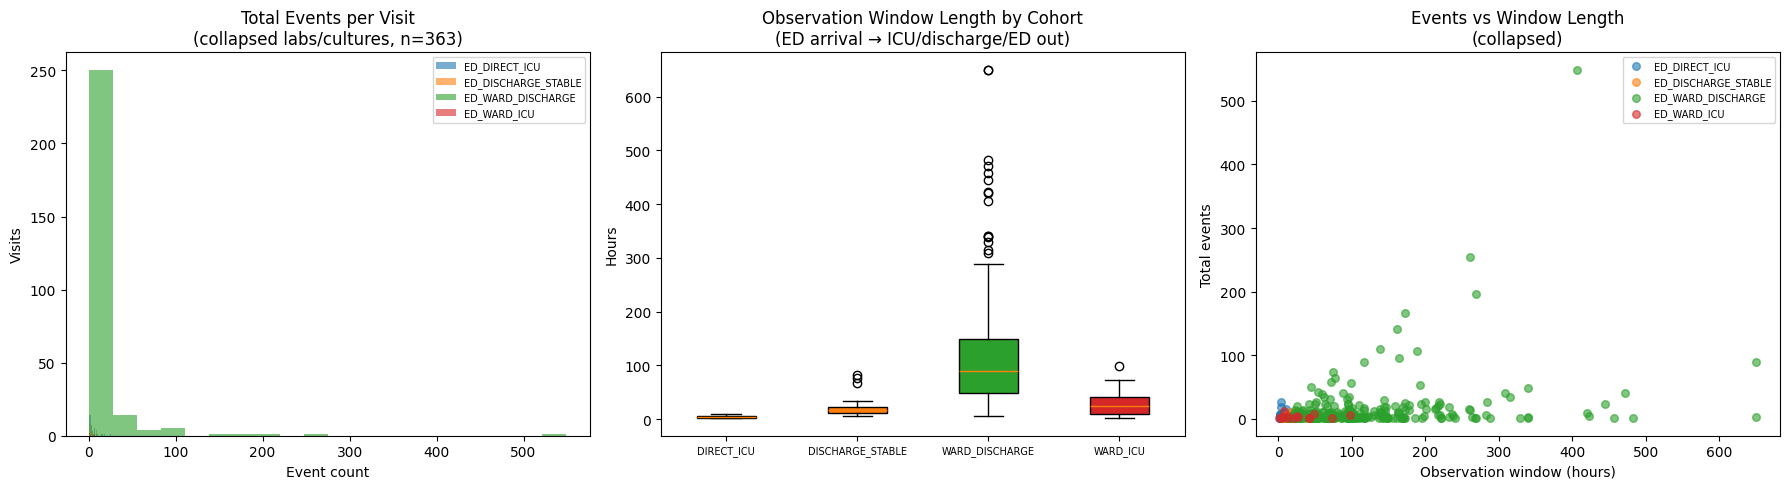


Top-level event type counts (collapsed):
event_type_top
administer_medication    2835
order_lab                1042
vital_signs               502
order_culture             147
stop_medication            56
start_medication           52
Name: count, dtype: int64


In [23]:
import matplotlib.pyplot as plt
import numpy as np

n_visits = df_events['hadm_id'].nunique()
print(f"Visits in sample: {n_visits}")

# ── 1. Total events per visit ─────────────────────────────────────────────────
events_per_visit = (
    df_events.groupby(['hadm_id', 'cohort_label'])
    .size()
    .rename('total_events')
    .reset_index()
)
print("\nTotal events per visit (all cohort labels):")
print(events_per_visit['total_events'].describe())
print("\nBy cohort label:")
print(events_per_visit.groupby('cohort_label')['total_events'].describe().round(1))

# ── 2. Window length in hours per visit ──────────────────────────────────────
window_hours = (
    df_events.groupby(['hadm_id', 'cohort_label'])
    .apply(lambda g: (g['observation_end'].iloc[0] - g['ed_intime'].iloc[0]).total_seconds() / 3600)
    .rename('window_hours')
    .reset_index()
)
print("\nObservation window length (hours) by cohort label:")
print(window_hours.groupby('cohort_label')['window_hours'].describe().round(1))

# ── 3. Plots ──────────────────────────────────────────────────────────────────
cohort_labels = sorted(events_per_visit['cohort_label'].unique())
colors = plt.cm.tab10.colors

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Total events per visit — histogram by cohort label
for i, label in enumerate(cohort_labels):
    subset = events_per_visit[events_per_visit['cohort_label'] == label]['total_events']
    axes[0].hist(subset, bins=20, alpha=0.6, label=label, color=colors[i])
axes[0].set_title(f'Total Events per Visit\n(collapsed labs/cultures, n={n_visits})')
axes[0].set_xlabel('Event count')
axes[0].set_ylabel('Visits')
axes[0].legend(fontsize=7)

# (b) Observation window length by cohort label — boxplot
window_by_label = [
    window_hours[window_hours['cohort_label'] == lbl]['window_hours'].values
    for lbl in cohort_labels
]
bp = axes[1].boxplot(window_by_label, labels=[l.replace('ED_', '') for l in cohort_labels],
                     patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
axes[1].set_title('Observation Window Length by Cohort\n(ED arrival → ICU/discharge/ED out)')
axes[1].set_ylabel('Hours')
axes[1].tick_params(axis='x', labelsize=7)

# (c) Events per visit vs window length (scatter, coloured by cohort)
merged = events_per_visit.merge(window_hours, on=['hadm_id', 'cohort_label'])
for i, label in enumerate(cohort_labels):
    sub = merged[merged['cohort_label'] == label]
    axes[2].scatter(sub['window_hours'], sub['total_events'],
                    alpha=0.6, label=label, color=colors[i], s=30)
axes[2].set_title('Events vs Window Length\n(collapsed)')
axes[2].set_xlabel('Observation window (hours)')
axes[2].set_ylabel('Total events')
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

# ── 4. Event type breakdown ───────────────────────────────────────────────────
df_events['event_type_top'] = df_events['event_type'].str.split(' | ').str[0]
print("\nTop-level event type counts (collapsed):")
print(df_events['event_type_top'].value_counts())